# Mapping San Francisco police incidents, 2016

Where and when were police incidents recorded in San Francisco in 2016, and which categories dominate? This notebook validates the SFPD extract, summarizes it by category, district and hour, and maps it with Folium. The logic lives in `analysis.py`.

In [1]:
import pandas as pd
from IPython.display import Image

import analysis

data, quality = analysis.load_incidents()
metrics = analysis.run(write_map=True)
pd.Series(quality, name='count').to_frame()

,count
offense_records,150500
distinct_incidents,116699
missing_coordinates,0
coordinates_outside_sf_bounding_box,0
unparsed_timestamps,0
duplicate_offense_ids,0
missing_district,1


## Offenses versus incidents

Each row is one offense. An incident can carry several offenses (for example a theft and a vandalism charge), so counting rows overstates incidents by about 29%.

In [2]:
print(f"{metrics['valid_offense_records']:,} offense records in {metrics['valid_incidents']:,} incidents "
      f"({metrics['offenses_per_incident_mean']:.2f} offenses per incident)")

150,500 offense records in 116,699 incidents (1.29 offenses per incident)


## Categories and districts

In [3]:
pd.read_csv('outputs/category_counts.csv').head(10)

,category,offense_records,incidents,share_of_incidents
0,LARCENY/THEFT,40409,39988,0.342659
1,NON-CRIMINAL,17866,17456,0.149581
2,OTHER OFFENSES,19599,17093,0.146471
3,ASSAULT,13577,11262,0.096505
4,VANDALISM,8589,8444,0.072357
5,VEHICLE THEFT,6419,5953,0.051012
6,SUSPICIOUS OCC,5782,5692,0.048775
7,BURGLARY,5802,5682,0.048689
8,WARRANTS,5914,5477,0.046933
9,ROBBERY,3299,3210,0.027507


In [4]:
pd.read_csv('outputs/district_counts.csv').assign(share=lambda d: d['share'].round(3))

,district,incidents,share
0,SOUTHERN,22239,0.191
1,NORTHERN,15997,0.137
2,MISSION,14500,0.124
3,CENTRAL,14418,0.124
4,BAYVIEW,10890,0.093
5,TARAVAL,8778,0.075
6,INGLESIDE,8691,0.074
7,RICHMOND,7306,0.063
8,TENDERLOIN,7038,0.060
9,PARK,6847,0.059


## Time of day

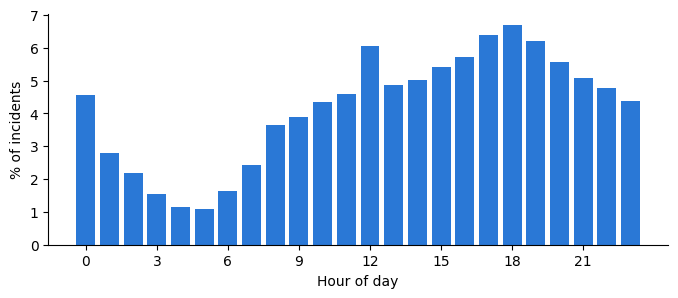

In [5]:
import matplotlib.pyplot as plt

hours = analysis.hourly_profile(data)
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(hours.index, hours.values * 100, color='#2a78d6', width=0.8)
ax.set_xlabel('Hour of day')
ax.set_ylabel('% of incidents')
ax.set_xticks(range(0, 24, 3))
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## Where incidents concentrate

All 116,699 incidents, binned into hexagons on a log color scale.

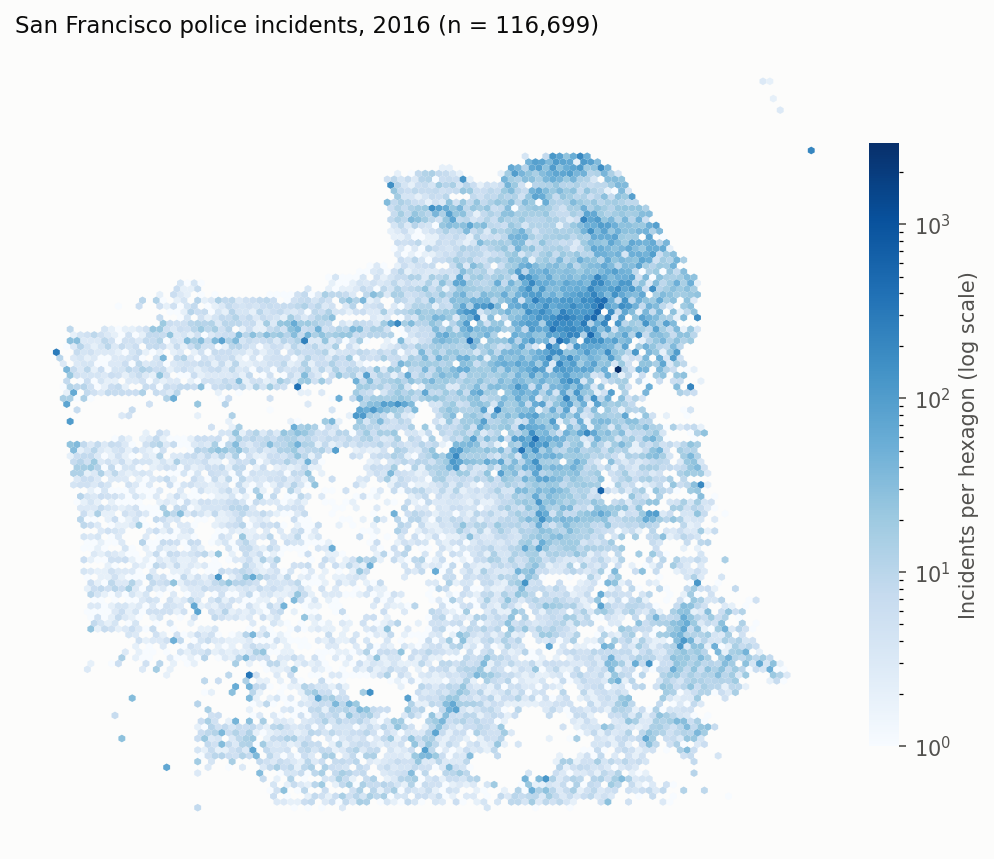

In [6]:
Image(filename='outputs/figures/incident_density.png', width=600)

## Interactive map

A seeded sample of 500 incidents, clustered with `MarkerCluster`. Folium maps don't render in GitHub's notebook preview; open the notebook in Jupyter or nbviewer, or open `outputs/incident_map.html` after running `python analysis.py --write-map`.

In [7]:
analysis.create_map(analysis.deterministic_map_sample(data))